# Combined benchmark and environment summary

This notebook consolidates the **benchmark-source studies plus the completed
expansion studies**. It does not treat “15 expansion studies” as the total
benchmark. The comparison is restricted to native **PICRUSt2** and
**Tax4Fun2** predictions; no fitting or training occurs.

The profile section uses source-project × biological-environment scopes so
technical strata do not inflate the study count. The group section uses only
accepted contrasts with usable labels and keeps paper-derived metric families
separate from repository extensions.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
from IPython.display import Image, display

cwd = Path.cwd().resolve()
if (cwd / "combined_benchmark").exists():
    REPO = cwd
elif cwd.name == "combined_benchmark":
    REPO = cwd.parent
else:
    candidates = [cwd, *cwd.parents]
    REPO = next(path for path in candidates if (path / "combined_benchmark").exists())
HERE = REPO / "combined_benchmark"
RESULTS = HERE / "results"
FIGURES = HERE / "figures"
METHODS = ["PICRUSt2", "Tax4Fun2"]

receipt = json.loads((HERE / "RUN_COMPLETE.json").read_text())
receipt

{'status': 'PASS',
 'training_performed': False,
 'methods': ['PICRUSt2', 'Tax4Fun2'],
 'paired_samples': 1717,
 'benchmark_source_samples': 621,
 'expansion_samples': 1096,
 'unique_source_projects': 24,
 'source_project_environment_scopes': 29,
 'accepted_biological_contrasts': 17,
 'profile_aggregation_policy': 'equal weight per source-project x environment scope for environment macro summaries',
 'blueberry_environment': 'Unknown (contradictory), retained from frozen source annotation',
 'benchmark_metric_recomputation': 'project BH and Sun metrics rerun from repository compact processed bundles',
 'source_trees_modified': False}

## 1. Coverage census

There are three deliberately different counts: unique source projects,
source-project × environment scopes, and paired samples. Profile metrics use
all paired samples, but the environment macro summary gives each scope equal
weight.

,quantity,value
0,paired samples,1717
1,benchmark-source samples,621
2,expansion samples,1096
3,unique source projects,24
4,source-project × environment scopes,29


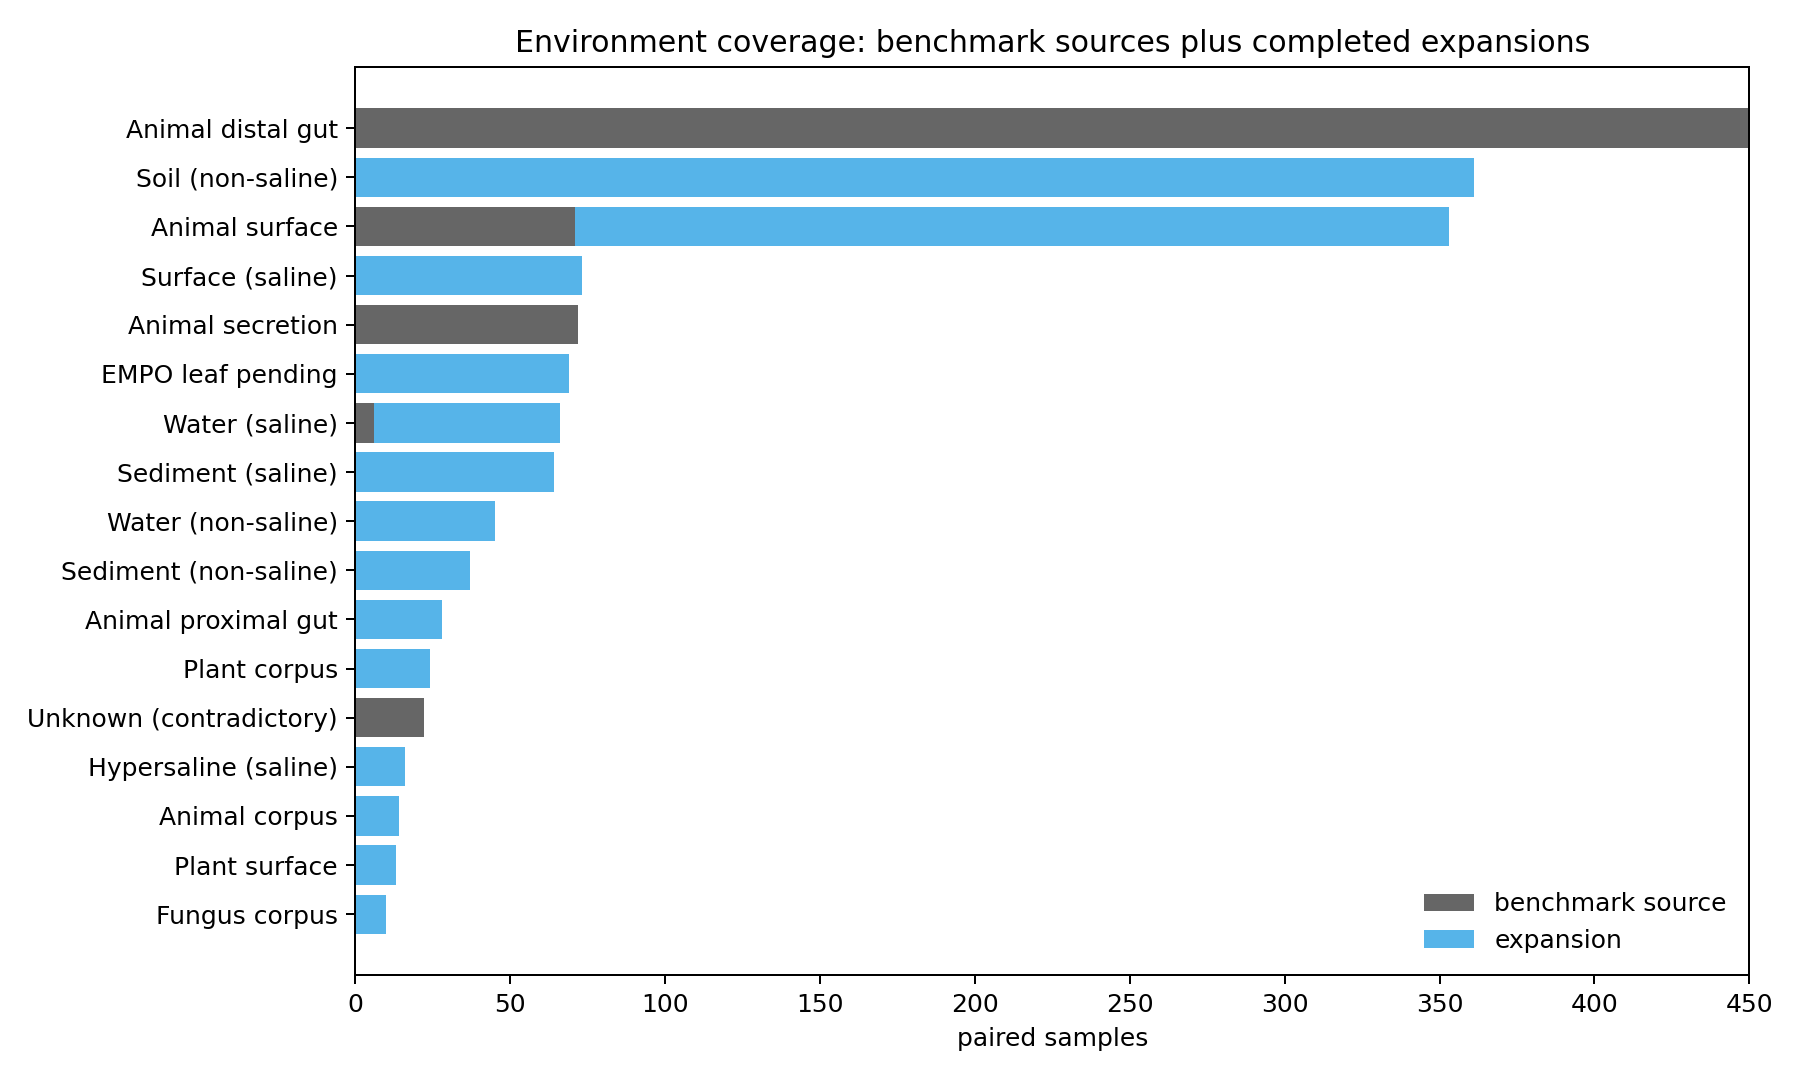

In [2]:
registry = pd.read_csv(RESULTS / "combined_sample_environment_registry.tsv.gz", sep="	")
scope = pd.read_csv(RESULTS / "scope_profile_summary.tsv", sep="	")
environment = pd.read_csv(RESULTS / "environment_profile_summary.tsv", sep="	")

census = pd.DataFrame({
    "quantity": ["paired samples", "benchmark-source samples", "expansion samples",
                 "unique source projects", "source-project × environment scopes"],
    "value": [registry.sample_key.nunique(),
              registry.provenance.eq("benchmark_source").sum(),
              registry.provenance.eq("expansion").sum(),
              registry.source_project_id.nunique(),
              registry.environment_scope_id.nunique()],
})
display(census)
display(Image(filename=str(FIGURES / "01_environment_coverage_census.png"), width=1000))

## 2. Profile agreement by environment

The dumbbell plot reports the mean sample-wise Spearman correlation within
each source-project × environment scope. The paired-difference plot subtracts
PICRUSt2 from Tax4Fun2 within the same samples and uses deterministic 2,000-run
sample-bootstrap intervals. The macro panel then summarizes scope means—not
pooled samples—within the broad environment hierarchy.

method_label,empo_1,empo_2,empo_3,display_name,provenance,PICRUSt2,Tax4Fun2,Tax4Fun2_minus_PICRUSt2
0,Engineered,Not assigned,EMPO leaf pending,Activated sludge,expansion,0.691571,0.638166,-0.053405
1,Engineered,Not assigned,EMPO leaf pending,Engineered bioreactor,expansion,0.648165,0.620299,-0.027866
2,Free-living,Non-saline,Sediment (non-saline),EMP500 lake/stream sediment,expansion,0.591858,0.496490,-0.095368
3,Free-living,Non-saline,Soil (non-saline),Empty Quarter,expansion,0.681274,0.697203,0.015928
4,Free-living,Non-saline,Soil (non-saline),Topsoil,expansion,0.711843,0.666598,-0.045244
5,Free-living,Non-saline,Water (non-saline),Han River,expansion,0.671506,0.651193,-0.020313
6,Free-living,Saline,Hypersaline (saline),Bonneville Salt Flats,expansion,0.651634,0.595390,-0.056244
7,Free-living,Saline,Sediment (saline),EMP500 marine sediment,expansion,0.485169,0.435232,-0.049937
8,Free-living,Saline,Surface (saline),Plastic biofilm,expansion,0.580383,0.563178,-0.017205
9,Free-living,Saline,Water (saline),Ocean Sampling Day,expansion,0.561767,0.523833,-0.037934


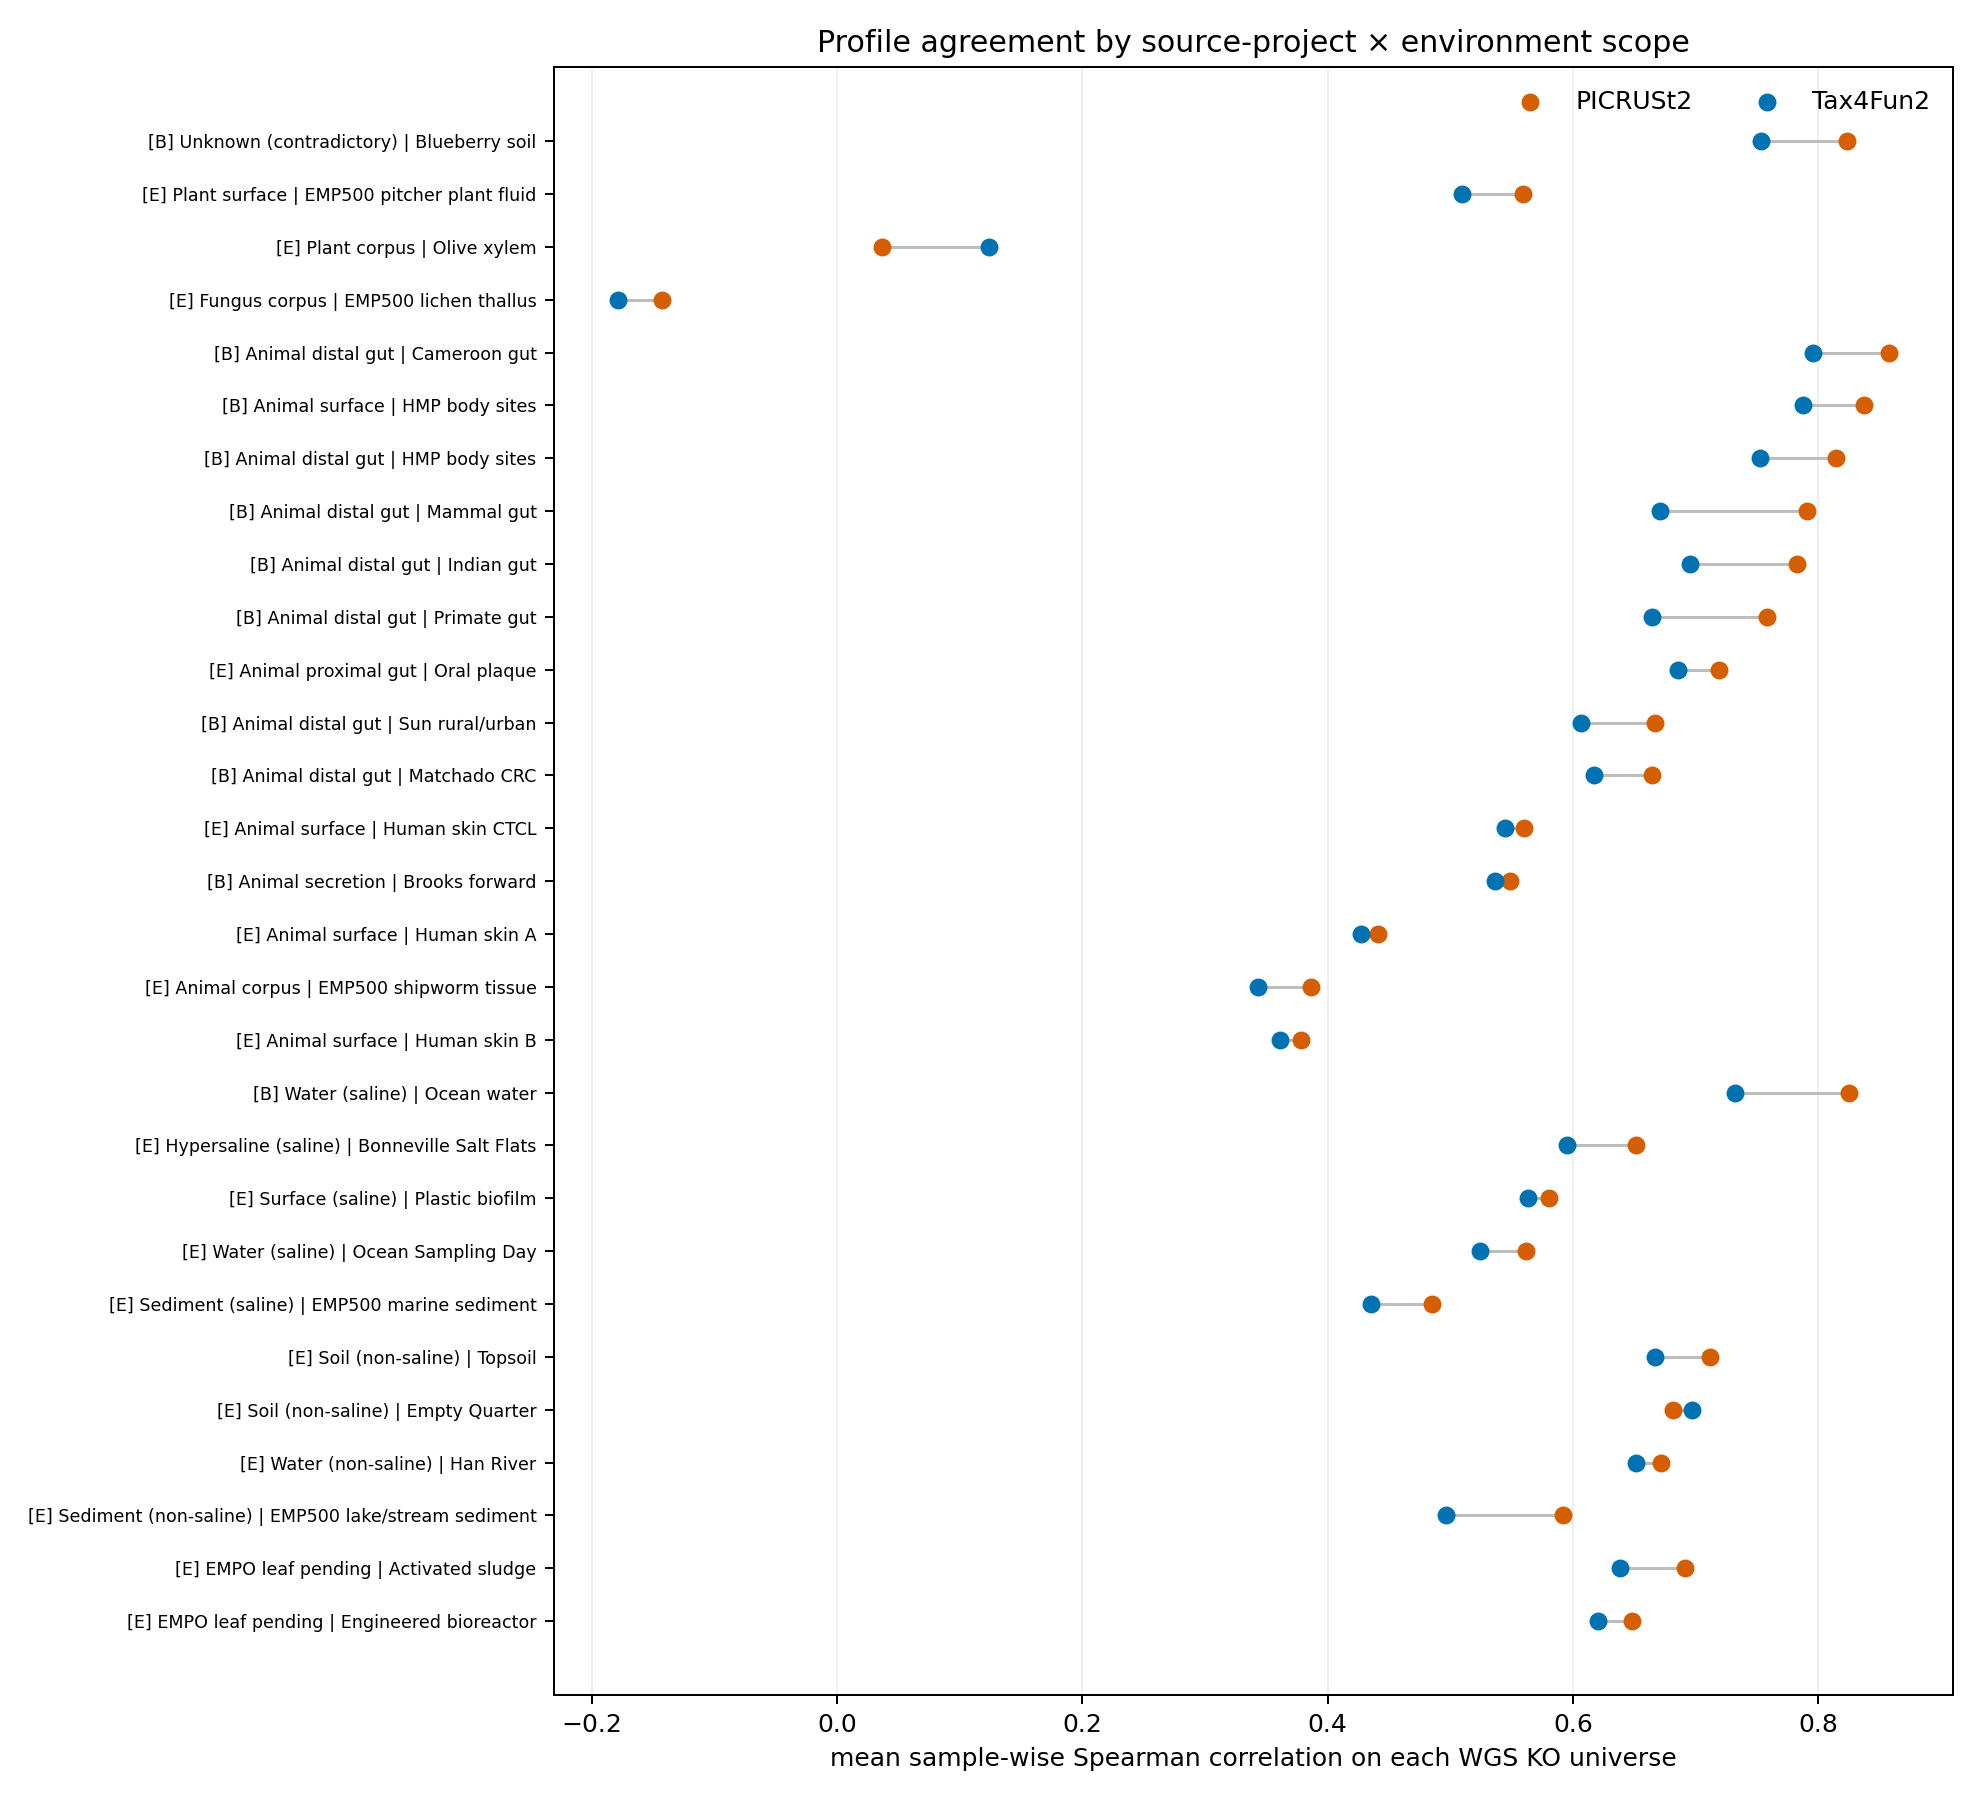

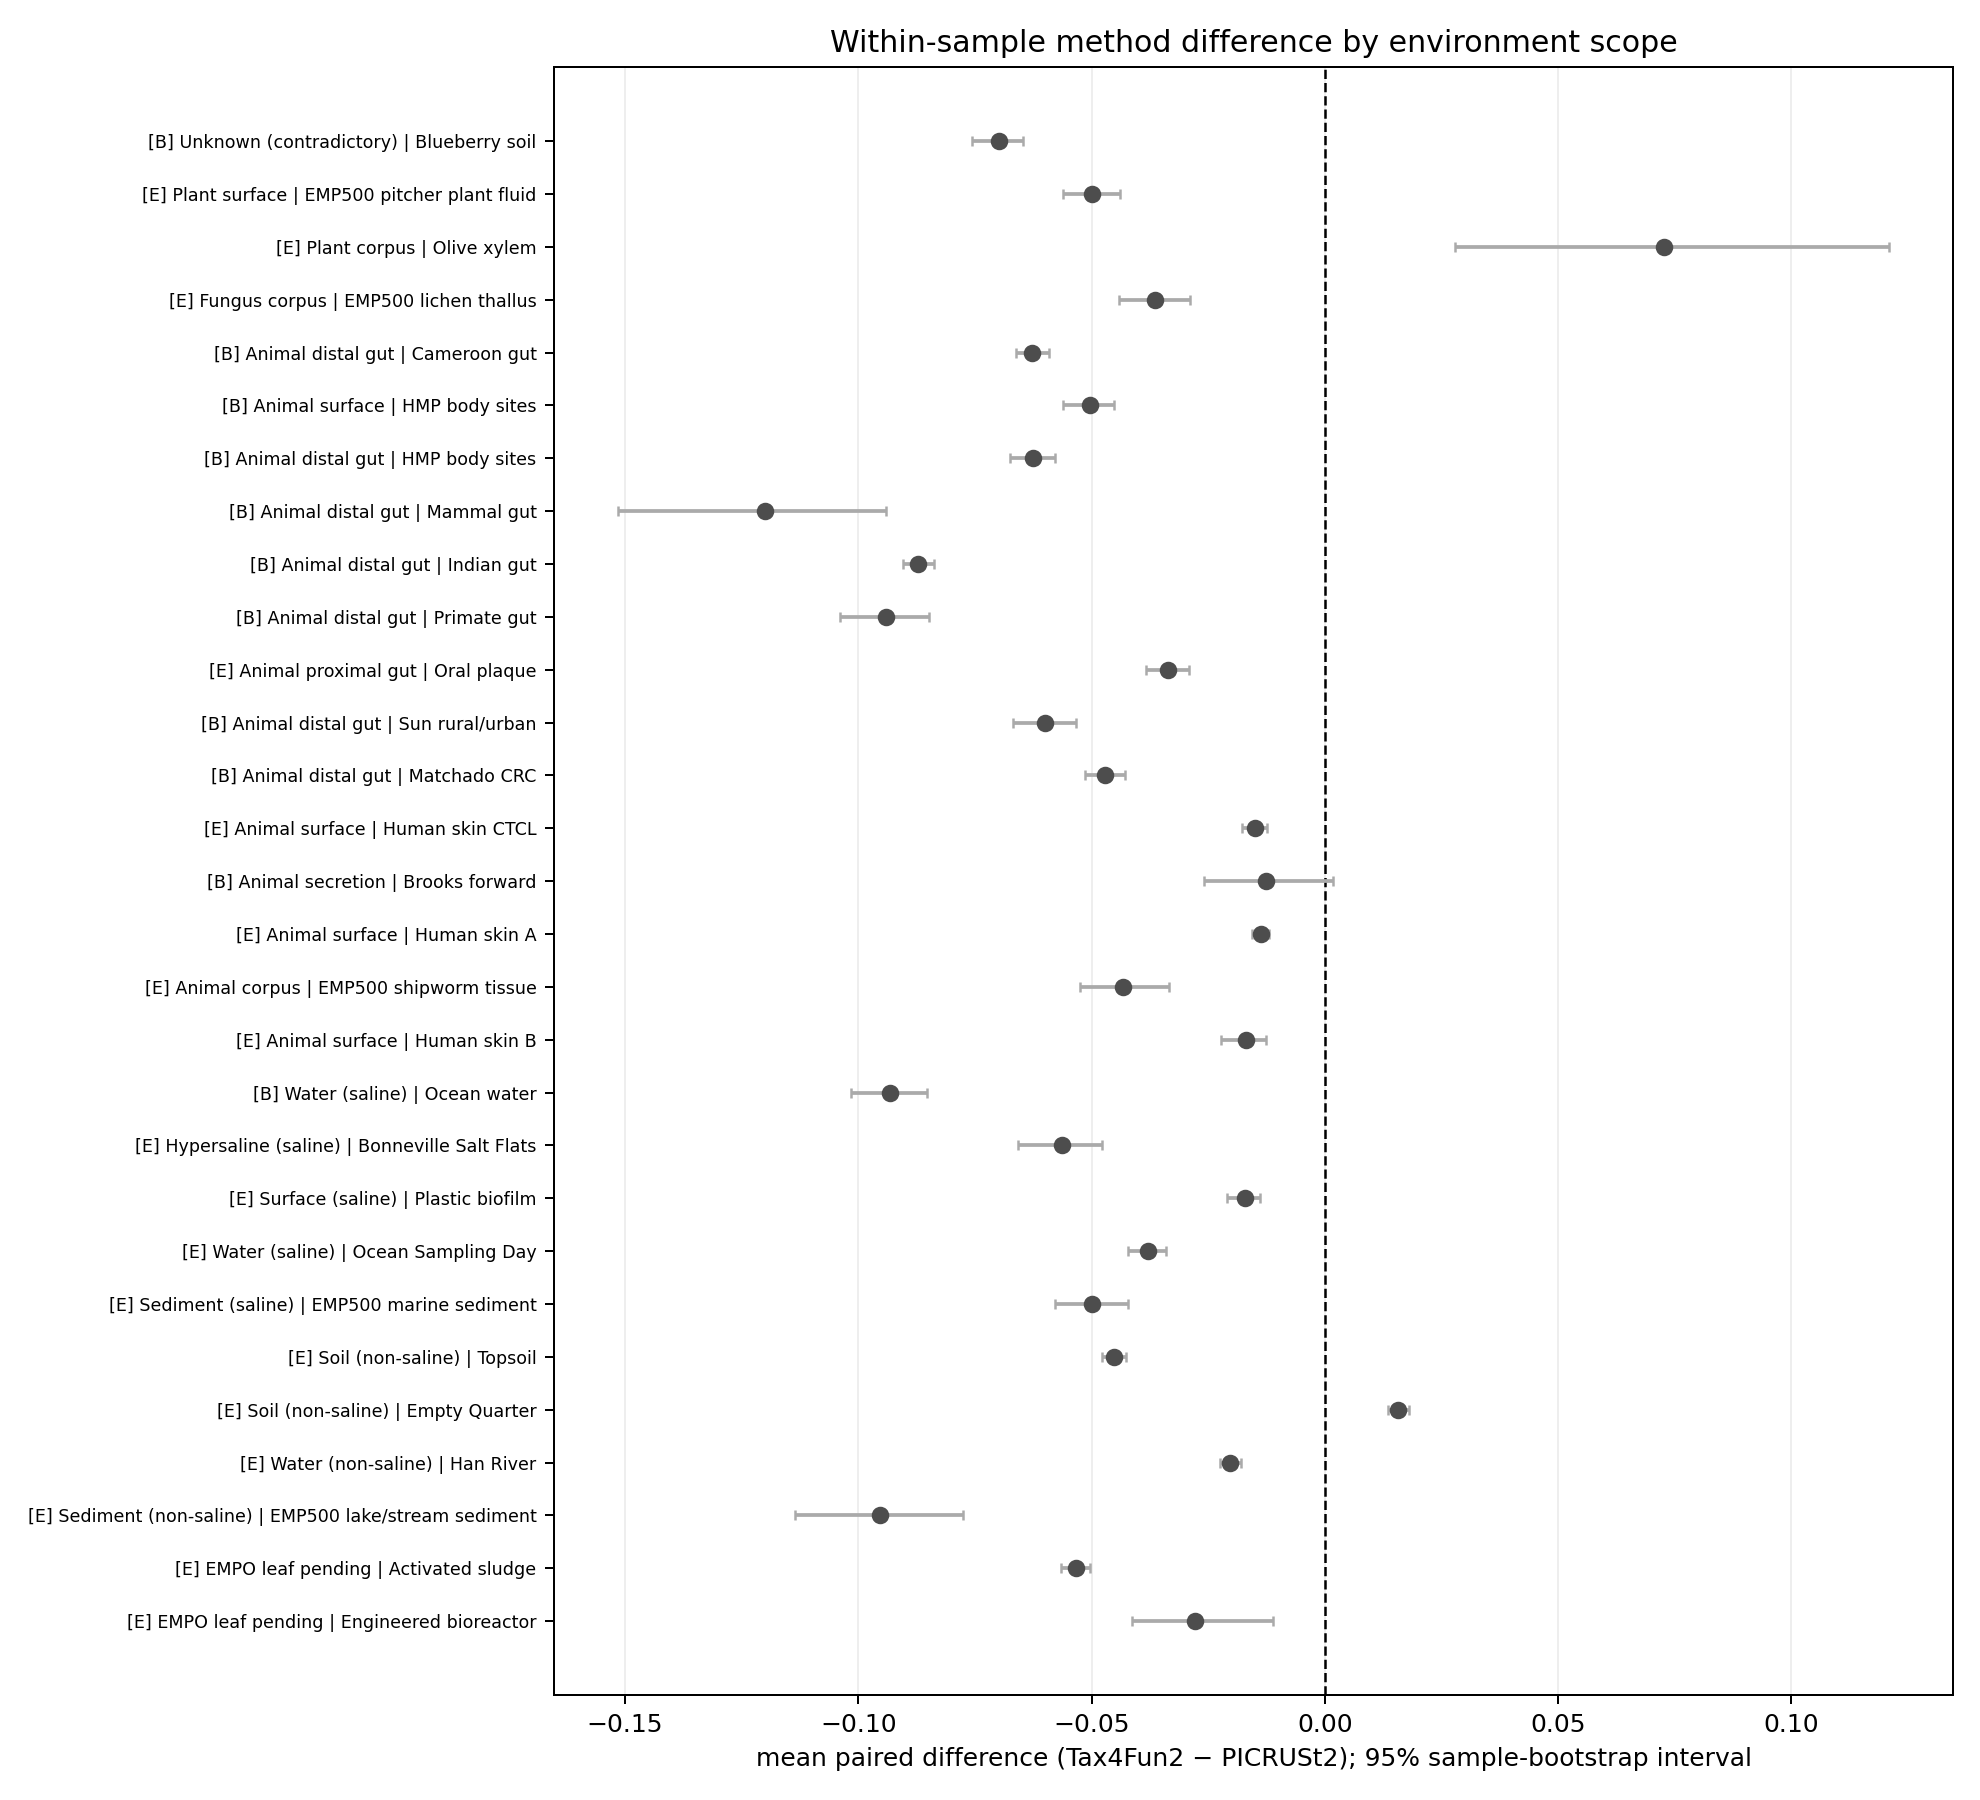

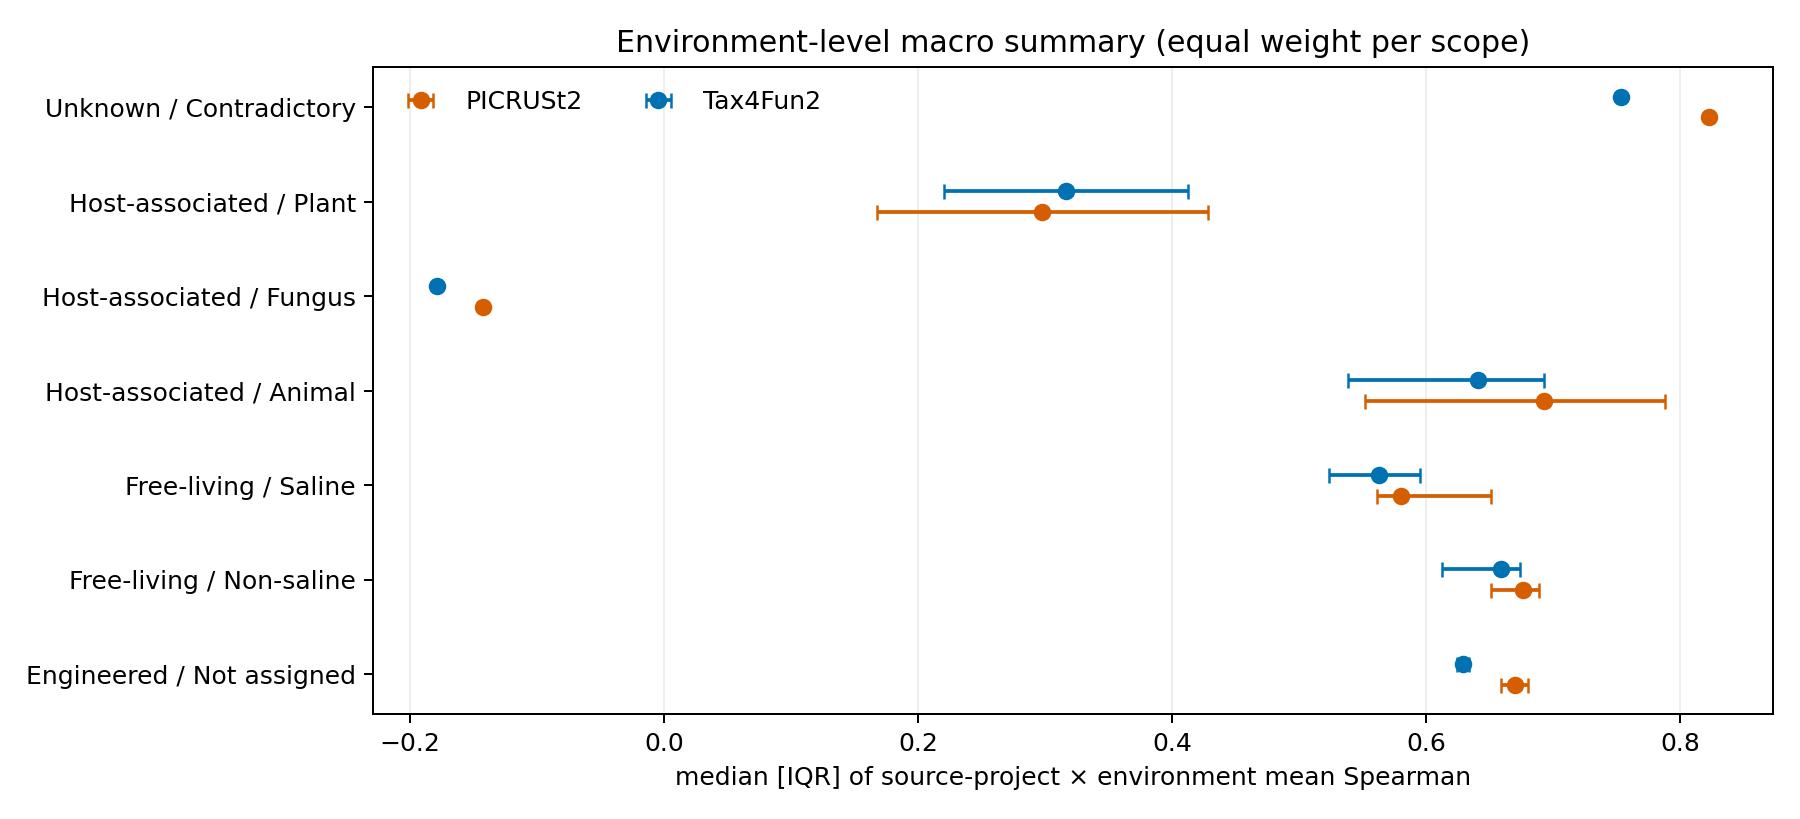

In [3]:
summary = scope.pivot_table(
    index=["empo_1", "empo_2", "empo_3", "display_name", "provenance"],
    columns="method_label", values="mean_sample_spearman"
).reset_index()
summary["Tax4Fun2_minus_PICRUSt2"] = summary["Tax4Fun2"] - summary["PICRUSt2"]
display(summary.sort_values(["empo_1", "empo_2", "empo_3", "display_name"]).reset_index(drop=True))
display(Image(filename=str(FIGURES / "02_scope_profile_dumbbell.png"), width=1050))
display(Image(filename=str(FIGURES / "03_scope_method_difference.png"), width=1050))
display(Image(filename=str(FIGURES / "04_environment_macro_profile.png"), width=950))

The figures are descriptive. A higher value for one method in one environment
scope is not evidence of universal method superiority. Scope means also have
different sampling precision, shown in the result table, while the macro
summary intentionally weights scopes equally.

## 3. Biological-group contrasts and metric availability

Eight original benchmark contrasts and nine completed expansion contrasts
form the 17-row registry. Matchado-style and Sun-style metrics require
unpaired two-group designs, so the three paired expansion contrasts appear in
the project effect/directional outputs but not those paper-derived families.
Tax4Fun2 olive-season-1 group results are unavailable because two prediction
samples have zero native totals; no value is imputed.

In [4]:
contrasts = pd.read_csv(RESULTS / "combined_contrast_registry.tsv", sep="	")
effect = pd.read_csv(RESULTS / "combined_effect.tsv", sep="	")
directional = pd.read_csv(RESULTS / "combined_directional.tsv", sep="	")
matchado = pd.read_csv(RESULTS / "combined_matchado.tsv", sep="	")
bh = pd.read_csv(RESULTS / "combined_bh.tsv", sep="	")
sun = pd.read_csv(RESULTS / "combined_sun.tsv", sep="	")

rows = []
for contrast in contrasts.itertuples(index=False):
    for method in METHODS:
        rows.append({
            "contrast_id": contrast.contrast_id,
            "provenance": contrast.provenance,
            "design": contrast.design,
            "method": method,
            "effect_directional": ((effect.contrast_id == contrast.contrast_id) & (effect.prediction_method == method)).any(),
            "matchado_raw_p": ((matchado.contrast_id == contrast.contrast_id) & (matchado.prediction_method == method)).any(),
            "project_bh": ((bh.contrast_id == contrast.contrast_id) & (bh.prediction_method == method)).any(),
            "sun": ((sun.contrast_id == contrast.contrast_id) & (sun.prediction_method == method)).any(),
        })
availability = pd.DataFrame(rows)
display(availability)

,contrast_id,provenance,design,method,effect_directional,matchado_raw_p,project_bh,sun
0,benchmark_blueberry,benchmark_source,unpaired,PICRUSt2,True,True,True,True
1,benchmark_blueberry,benchmark_source,unpaired,Tax4Fun2,True,True,True,True
2,benchmark_cameroon,benchmark_source,unpaired,PICRUSt2,True,True,True,True
3,benchmark_cameroon,benchmark_source,unpaired,Tax4Fun2,True,True,True,True
4,benchmark_hmp,benchmark_source,unpaired,PICRUSt2,True,True,True,True
5,benchmark_hmp,benchmark_source,unpaired,Tax4Fun2,True,True,True,True
6,benchmark_indian,benchmark_source,unpaired,PICRUSt2,True,True,True,True
7,benchmark_indian,benchmark_source,unpaired,Tax4Fun2,True,True,True,True
8,benchmark_primate,benchmark_source,unpaired,PICRUSt2,True,True,True,True
9,benchmark_primate,benchmark_source,unpaired,Tax4Fun2,True,True,True,True


## 4. Paper-derived metric families

The Matchado-style rows use unadjusted two-sided *p* < 0.05, WGS-significant
KOs as the reference, and 20 prediction-label randomizations. The Sun-style
rows correlate signed `log10(p)` group statistics and compare the observation
with 100 independent WGS KO-abundance shuffles. These definitions and plot
grammars are credited to the cited papers; applying them to this study set and
to Tax4Fun2 is the repository's implementation.

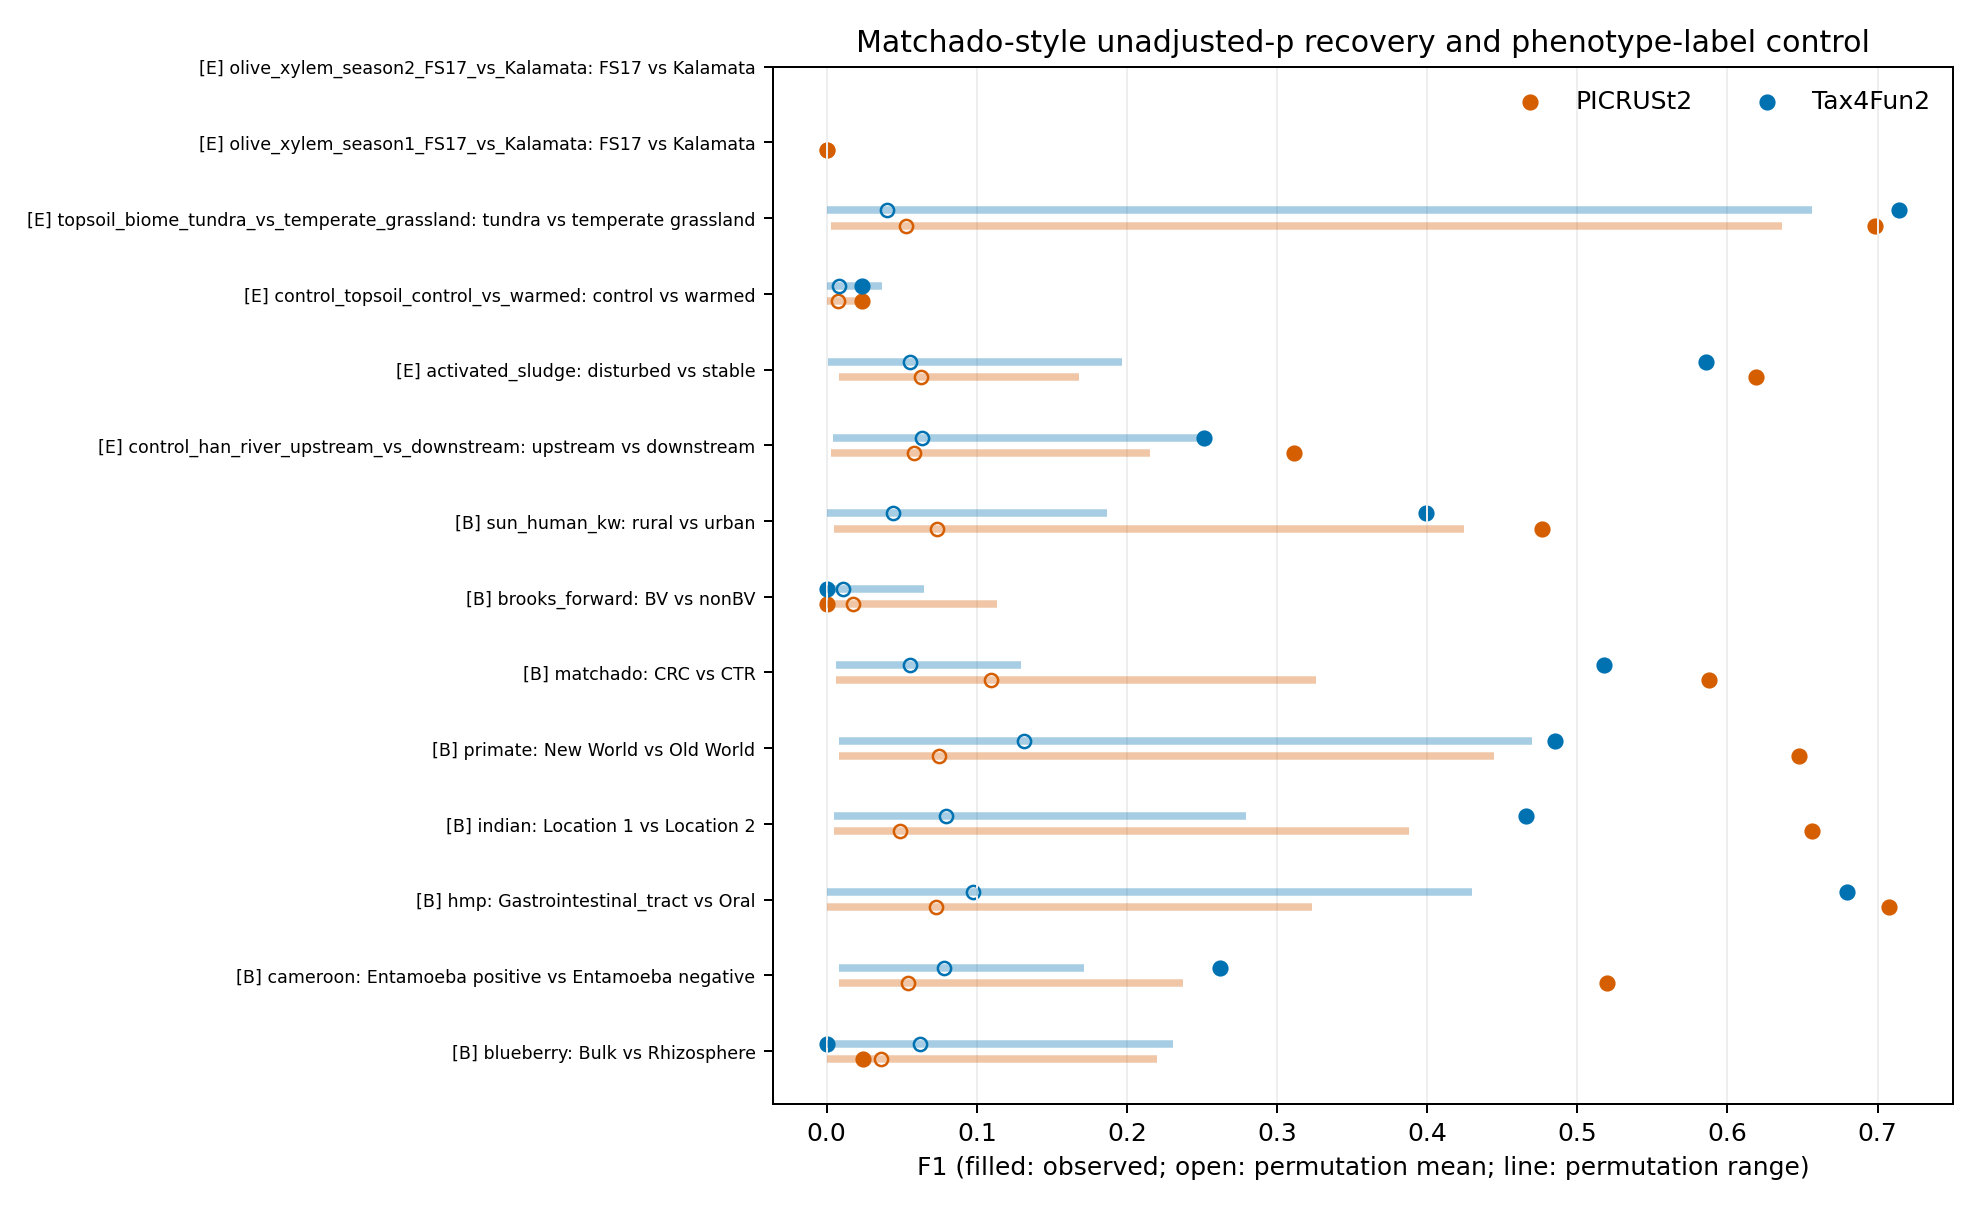

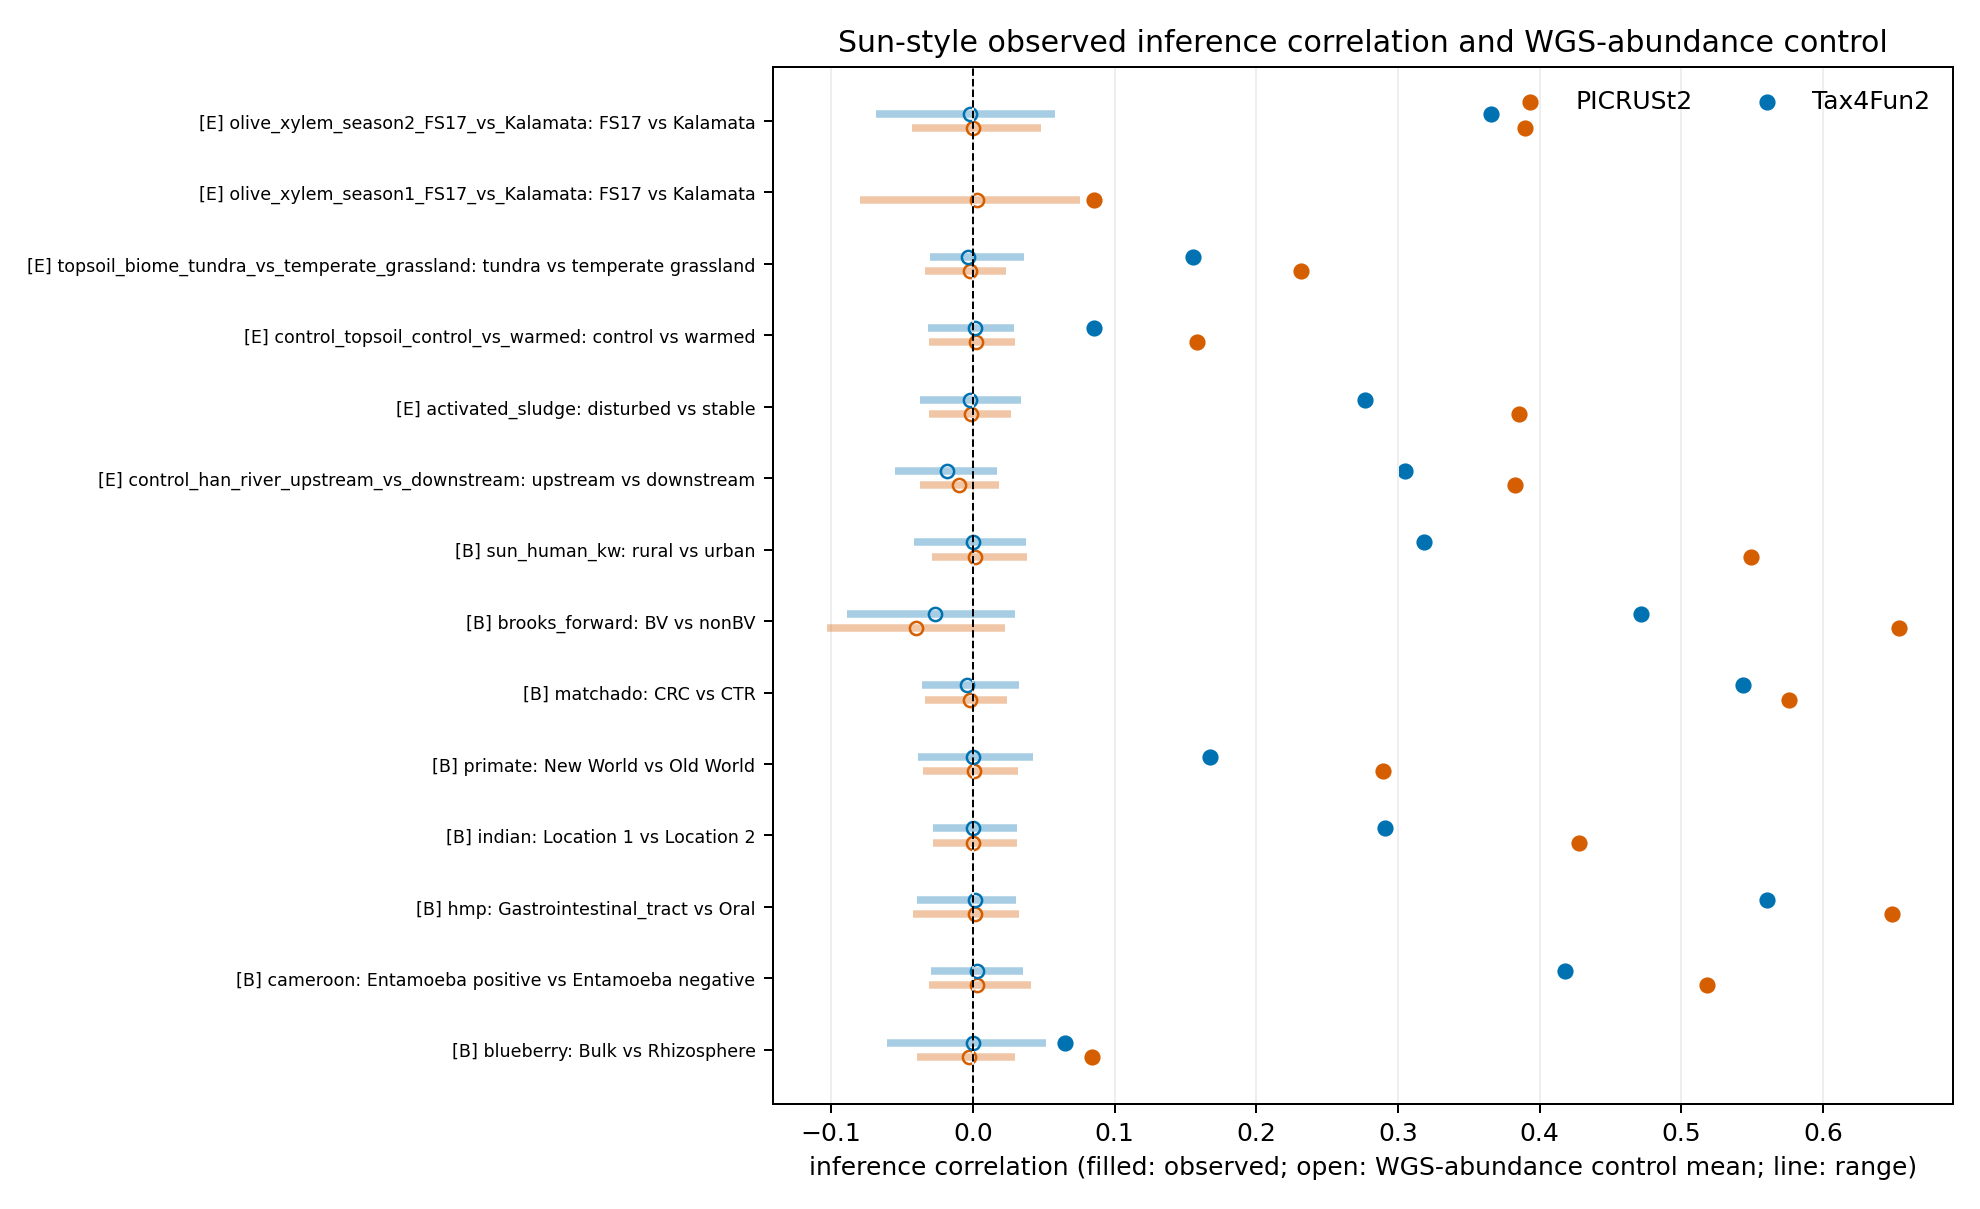

In [5]:
display(Image(filename=str(FIGURES / "05_matchado_raw_p_f1.png"), width=1050))
display(Image(filename=str(FIGURES / "06_sun_inference_correlation.png"), width=1050))

## 5. Repository extensions

The effect-size relation, directional ROC/precision-recall metrics, and BH
recovery table are repository extensions. They are not attributed to
PICRUSt/PICRUSt2, Sun, Matchado, or Tax4Fun2. BH is applied within each complete
KO family and uses *q* < 0.05 to limit the expected false-discovery proportion
across simultaneous KO tests.

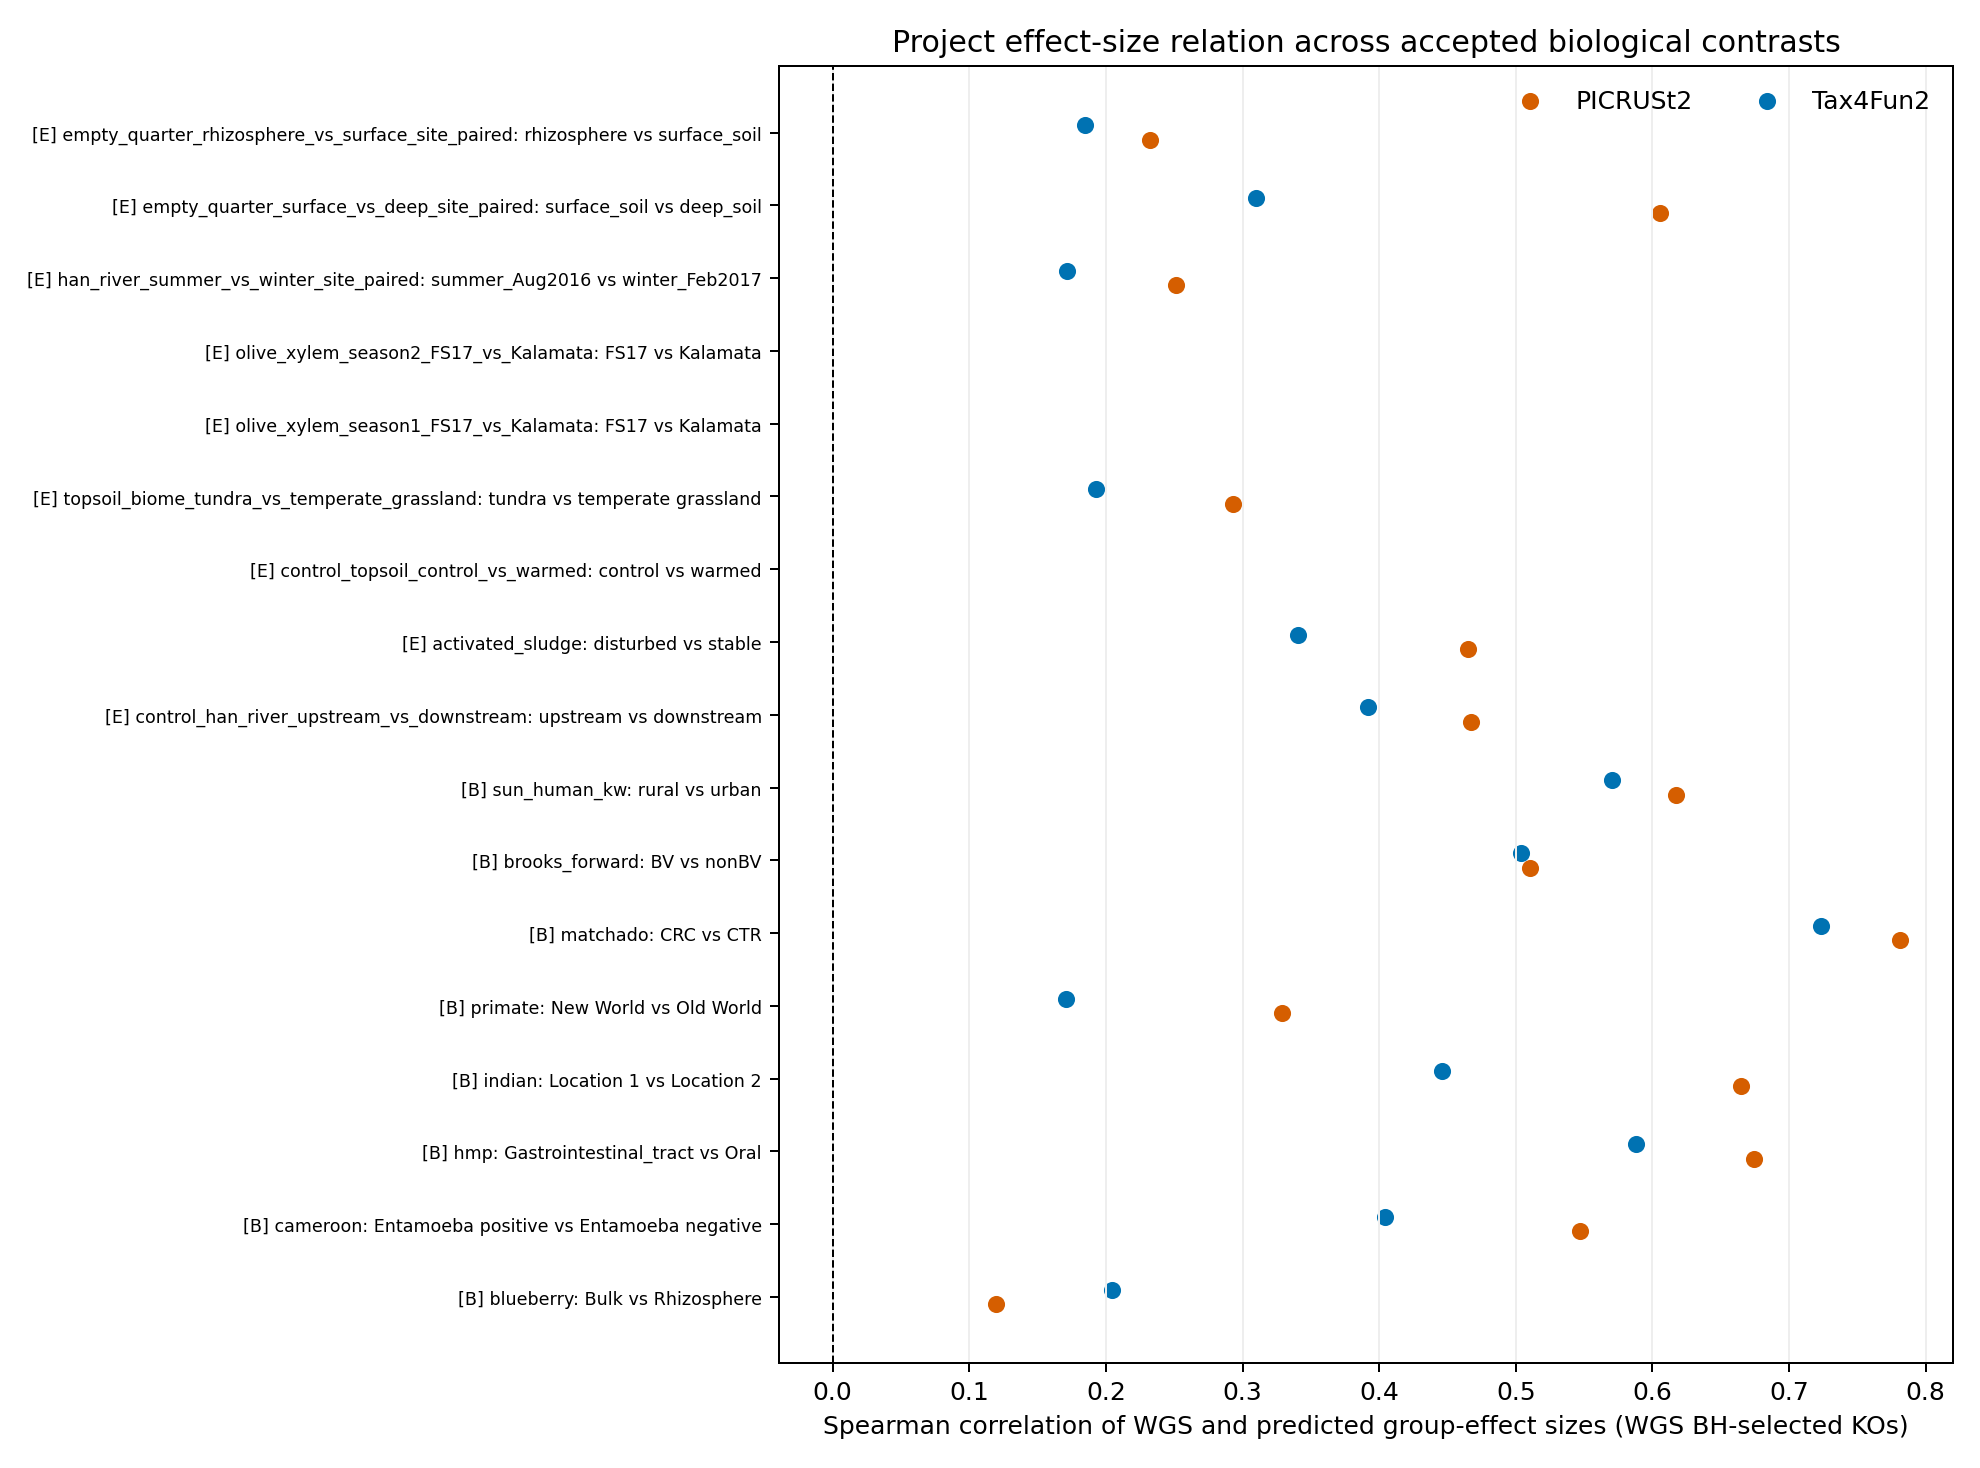

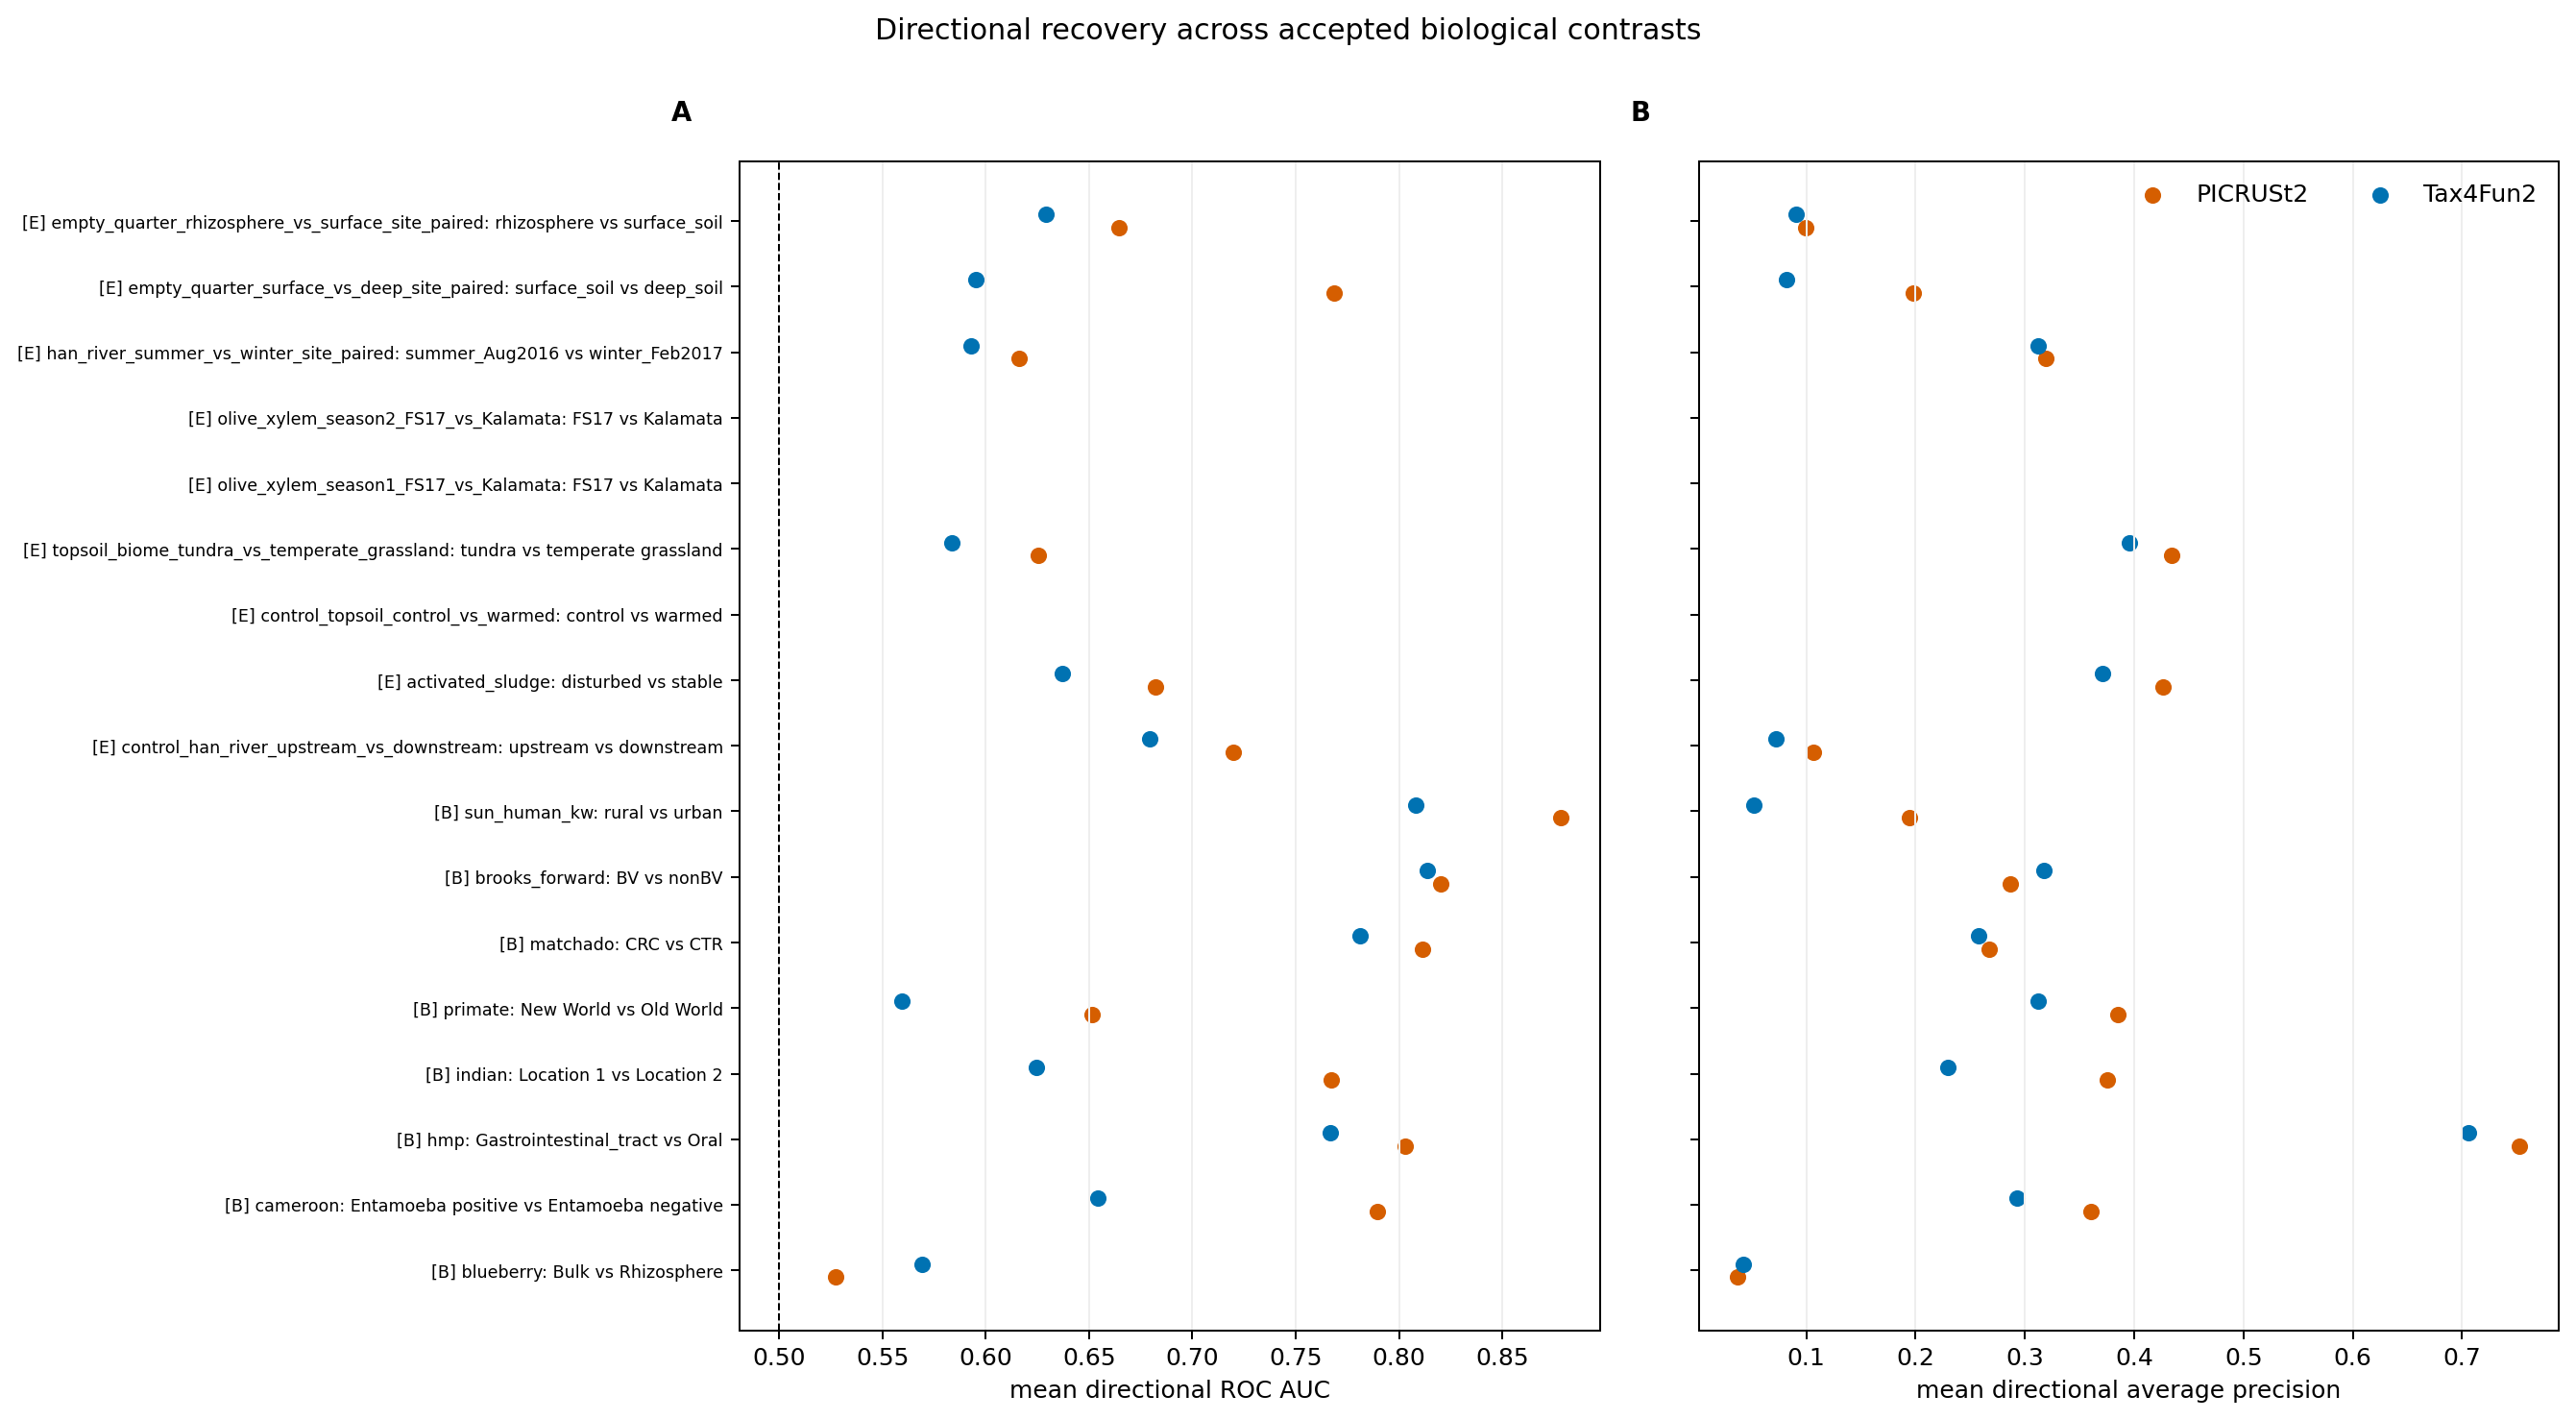

In [6]:
display(Image(filename=str(FIGURES / "07_effect_relationship.png"), width=1050))
display(Image(filename=str(FIGURES / "08_directional_roc_auc.png"), width=1200))

## 6. Numerical validation

The validator checks all input/output hashes, census invariants, explicit
unavailable values, and completed-result agreement at absolute tolerance
`1e-12`. It also verifies the newly recomputed original PICRUSt2 effect and
directional rows against the frozen completed references before accepting the
parallel Tax4Fun2 calculations.

In [7]:
validation = subprocess.run(
    [sys.executable, str(HERE / "validate_outputs.py")],
    cwd=REPO, check=True, capture_output=True, text=True,
)
print(validation.stdout)

{
  "status": "PASS",
  "tolerance": 1e-12,
  "max_abs_diff_profile_benchmark_picrust2": 0.0,
  "max_abs_diff_profile_benchmark_tax4fun2": 0.0,
  "max_abs_diff_profile_expansion": 0.0,
  "max_abs_diff_effect_picrust2_reference": 0.0,
  "max_abs_diff_directional_roc_picrust2_reference": 2.220446049250313e-16,
  "max_abs_diff_directional_ap_picrust2_reference": 1.1102230246251565e-16,
  "input_hashes_verified": 45,
  "output_hashes_verified": 22
}



## 7. Choices to resolve before a manuscript-wide primary summary

- Retain the frozen EMPO-style hierarchy or conduct a separate reviewed
  environment-ontology pass.
- Keep equal scope weights (current), use sample weights, or fit a hierarchical
  model. Each estimates a different target.
- Place provisional/control expansion contrasts in the main figure or a
  supplement.
- Keep Brooks reverse-read results supplemental (current main-plot choice) or
  show forward and reverse technical strata together.

These are scientific presentation choices, not missing computations.